<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FCoral-reef-health-monitoring/notebooks/C3_Day2b_Improvements.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Component 3 – Day 2b: Improvements (before vs after)
Day 2 baseline: **SVM, macro-F1 0.51**. Me notebook eken improvements 3k test karanawa:

| Experiment | Composite | Label purity filter | Features |
|---|---|---|---|
| **E0** baseline | v1 (Day 1) | – | pixel (glint-corrected B2/B3/B4) |
| **E1** | **v2 (cleaner)** | – | pixel |
| **E2** | v2 | **≥ 0.75** | pixel |
| **E3** | v2 | ≥ 0.75 | **pixel + neighbourhood (3×3, 5×5)** |

Hama experiment ekakatama RF / SVM / XGBoost, **ekama 5-fold spatial CV**. Hodama eka save karala, maps walata **majority filter** (salt-and-pepper ain karanna) danawa.

**Earth Engine ona nehe.** Day 1b exports (v2 files 4) Drive eke thiyenna ona. Nathnam notebook eka v1 eken witharak run wenawa.
Runtime: ~5–10 min. Outputs → `coral_c3/results_v2/` saha `coral_c3/models/`.

## Part 0 – Setup

In [1]:
!pip install -q rasterio xgboost
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, json, time, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio, joblib
from scipy.ndimage import uniform_filter

BASE = '/content/drive/MyDrive/coral_c3'
RES, MOD = f'{BASE}/results_v2', f'{BASE}/models'
os.makedirs(RES, exist_ok=True); os.makedirs(MOD, exist_ok=True)

SITES = ['HKD', 'PGI']
CLASS_NAMES = {11: 'Sand', 12: 'Rubble', 13: 'Rock', 14: 'Seagrass', 15: 'Coral/Algae', 18: 'Microalgal Mats'}
CLASS_COLORS = {11: '#f4e4b0', 12: '#b0a99f', 13: '#5f6b7a', 14: '#3f9c4a', 15: '#ff7f50', 18: '#8b5a2b'}
CODES = [11, 12, 13, 15]             # same 4 classes as Day 2 (Seagrass too rare)
N_PER_CLASS, MIN_PURITY, SEED = 300, 0.75, 42

FILES = {v: {s: (f'{BASE}/S2_{s}_composite{sfx}.tif', f'{BASE}/ACA_{s}_label{sfx}.tif') for s in SITES}
         for v, sfx in [('v1', ''), ('v2', '_v2')]}
HAS_V2 = all(os.path.exists(p) for pair in FILES['v2'].values() for p in pair)
print('v1 files OK:', all(os.path.exists(p) for pair in FILES['v1'].values() for p in pair))
print('v2 files OK:', HAS_V2, '' if HAS_V2 else '→ Day 1b exports nehe; v1 eken witharak run wenawa (purity = 3×3 proxy)')

v1 files OK: True
v2 files OK: True 


✅ **Check:** `v1 files OK: True`, `v2 files OK: True`.

## Part A – Feature engineering (app.py ekath **ekama code eka** use karanawa)
- **Sunglint correction** (Hedley): image eke deep water pixels walin
- **Neighbourhood features**: glint-corrected B2/B3/B4 walata 3×3 & 5×5 mean saha 5×5 std (texture/context)

In [3]:
def estimate_glint(arr, dark_pct=10):
    b2, b3, b4, b8 = arr[0], arr[1], arr[2], arr[3]
    valid = np.isfinite(b2) & np.isfinite(b3) & np.isfinite(b4) & np.isfinite(b8)
    dark = b3 - b8
    deep = valid & (dark <= np.nanpercentile(dark[valid], dark_pct))
    nir = b8[deep]
    g = {'min_nir': float(np.percentile(nir, 1)), 'n_deep': int(deep.sum())}
    for name, b in zip(['B2', 'B3', 'B4'], [b2, b3, b4]):
        g[name] = float(np.clip(np.polyfit(nir, b[deep], 1)[0], 0, 2))
    return g

def nanmean_filter(x, size):
    valid = np.isfinite(x)
    num = uniform_filter(np.where(valid, x, 0.0).astype('float64'), size=size, mode='nearest')
    den = uniform_filter(valid.astype('float64'), size=size, mode='nearest')
    with np.errstate(invalid='ignore', divide='ignore'):
        m = num / den
    m[den < 0.5] = np.nan
    return m.astype('float32')

def nanstd_filter(x, size):
    m, m2 = nanmean_filter(x, size), nanmean_filter(x * x, size)
    return np.sqrt(np.clip(m2 - m * m, 0, None))

def feature_maps(arr, spec):
    """arr: (bands, H, W) reflectance [B2,B3,B4,B8,...]. Returns dict name -> (H, W) map, and glint params."""
    g = estimate_glint(arr, spec.get('glint_dark_pct', 10))
    f = {}
    for i, b in enumerate(['B2', 'B3', 'B4']):
        f[b] = arr[i]
        f[b + 'g'] = np.clip(arr[i] - g[b] * (arr[3] - g['min_nir']), 1e-4, None)
    f['r23'] = np.log(f['B2g']) - np.log(f['B3g'])
    f['r24'] = np.log(f['B2g']) - np.log(f['B4g'])
    sizes = spec.get('neigh_sizes', [])
    for b in ['B2g', 'B3g', 'B4g']:
        for k in sizes:
            f[f'{b}_m{k}'] = nanmean_filter(f[b], k)
        if sizes:
            f[f'{b}_s{max(sizes)}'] = nanstd_filter(f[b], max(sizes))
    return f, g

def read_composite(path):
    with rasterio.open(path) as src:
        arr = src.read().astype('float32'); prof = src.profile
    arr[arr <= 0] = np.nan
    return arr / 10000.0, prof

def read_label(path):
    with rasterio.open(path) as src:
        lab = src.read(1)
        pur = src.read(2).astype('float32') / 100 if src.count >= 2 else None
    if pur is None:   # v1: proxy = share of 3x3 neighbours with the same label
        pur = np.zeros(lab.shape, 'float32')
        for c in np.unique(lab[lab > 0]):
            same = uniform_filter((lab == c).astype('float32'), 3, mode='nearest')
            pur[lab == c] = same[lab == c]
    return lab, pur

PIX = ['B2g', 'B3g', 'B4g']
CONTEXT = PIX + [f'{b}_m{k}' for b in PIX for k in (3, 5)] + [f'{b}_s5' for b in PIX]
SPEC_FULL = {'glint_dark_pct': 10, 'neigh_sizes': [3, 5]}

data = {}
for v in (['v1', 'v2'] if HAS_V2 else ['v1']):
    for s in SITES:
        arr, prof = read_composite(FILES[v][s][0])
        lab, pur = read_label(FILES[v][s][1])
        fmaps, g = feature_maps(arr, SPEC_FULL)
        data[(v, s)] = dict(arr=arr, prof=prof, lab=lab, pur=pur, f=fmaps, g=g)
        reef = np.isin(lab, CODES)
        print(f'{v} {s}: shape {arr.shape[1:]}, reef px {reef.sum():,}, mean purity {pur[reef].mean():.2f}, '
              f'nodata in reef {(~np.isfinite(arr[0][reef])).mean():.1%}, glint B2 slope {g["B2"]:.2f}')

v1 HKD: shape (278, 278), reef px 11,104, mean purity 0.83, nodata in reef 5.7%, glint B2 slope 0.78
v1 PGI: shape (775, 662), reef px 8,148, mean purity 0.85, nodata in reef 3.5%, glint B2 slope 0.62
v2 HKD: shape (278, 278), reef px 11,104, mean purity 0.94, nodata in reef 5.5%, glint B2 slope 0.59
v2 PGI: shape (775, 662), reef px 8,148, mean purity 0.96, nodata in reef 3.0%, glint B2 slope 0.63


✅ **Check:** v1 + v2 site dekatama print wenawa. **`nodata in reef`** v2 eke v1 ta wada podi wenna puluwan (clear obs < 3 pixels ain kala nisa).

## Part B – Sampling (raster walin kelinma) + spatial blocks

In [4]:
def build_dataset(version, min_purity, feats):
    rng = np.random.default_rng(SEED)
    rows = []
    for s in SITES:
        d = data[(version, s)]
        X = np.stack([d['f'][k] for k in feats], axis=-1)
        ok = np.isfinite(X).all(-1)
        tr = d['prof']['transform']
        for c in CODES:
            idx = np.flatnonzero((d['lab'] == c).ravel() & ok.ravel() & (d['pur'] >= min_purity).ravel())
            if len(idx) == 0:
                continue
            pick = rng.choice(idx, min(N_PER_CLASS, len(idx)), replace=False)
            r, col = np.unravel_index(pick, d['lab'].shape)
            xs, ys = tr * (col + 0.5, r + 0.5)
            part = pd.DataFrame(X.reshape(-1, len(feats))[pick], columns=feats)
            part['label'], part['site'], part['x'], part['y'] = c, s, xs, ys
            rows.append(part)
    df = pd.concat(rows, ignore_index=True)
    df['block'] = df['site'] + '_' + (df['x'] // 500).astype(int).astype(str) + '_' + (df['y'] // 500).astype(int).astype(str)
    return df

V2 = 'v2' if HAS_V2 else 'v1'
EXPERIMENTS = [('E0_v1_pixel', 'v1', 0.0, PIX)]
if HAS_V2:
    EXPERIMENTS.append(('E1_v2_pixel', 'v2', 0.0, PIX))
EXPERIMENTS += [(f'E2_{V2}_pure', V2, MIN_PURITY, PIX), (f'E3_{V2}_pure_context', V2, MIN_PURITY, CONTEXT)]

datasets = {}
for name, v, p, feats in EXPERIMENTS:
    datasets[name] = build_dataset(v, p, feats)
    d = datasets[name]
    print(f'{name:22s} n={len(d):5d}  blocks={d.block.nunique():3d}  per class:',
          d.groupby('label').size().rename(index=CLASS_NAMES).to_dict())

E0_v1_pixel            n= 2400  blocks= 33  per class: {'Sand': 600, 'Rubble': 600, 'Rock': 600, 'Coral/Algae': 600}
E1_v2_pixel            n= 2400  blocks= 36  per class: {'Sand': 600, 'Rubble': 600, 'Rock': 600, 'Coral/Algae': 600}
E2_v2_pure             n= 2400  blocks= 34  per class: {'Sand': 600, 'Rubble': 600, 'Rock': 600, 'Coral/Algae': 600}
E3_v2_pure_context     n= 2400  blocks= 35  per class: {'Sand': 600, 'Rubble': 600, 'Rock': 600, 'Coral/Algae': 600}


✅ **Check:** experiment ekakata samples ~2,000–2,400. Purity filter eken samples tikak adu wenawa (normal).

## Part C – Train + compare (spatial 5-fold CV)

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

def get_models():
    return {
        'RandomForest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced',
                                               random_state=SEED, n_jobs=-1),
        'SVM': make_pipeline(StandardScaler(), SVC(C=10, gamma='scale', class_weight='balanced')),
        'XGBoost': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
                                 colsample_bytree=0.8, eval_metric='mlogloss', random_state=SEED, n_jobs=-1),
    }

le = LabelEncoder().fit(CODES)
labels_txt = [CLASS_NAMES[c] for c in CODES]
rows, preds = [], {}
for name, v, p, feats in EXPERIMENTS:
    df = datasets[name]
    X, y = df[feats].values, le.transform(df['label'])
    splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y, df['block']))
    for mname, model in get_models().items():
        t0 = time.perf_counter()
        pr = cross_val_predict(model, X, y, cv=splits)
        preds[(name, mname)] = (y, pr)
        rows.append({'experiment': name, 'model': mname, 'accuracy': accuracy_score(y, pr),
                     'macro_f1': f1_score(y, pr, average='macro'), 'kappa': cohen_kappa_score(y, pr),
                     'n_samples': len(y), 'cv_time_s': round(time.perf_counter() - t0, 1)})
        print(f'{name:22s} {mname:13s} OA={rows[-1]["accuracy"]:.3f}  F1={rows[-1]["macro_f1"]:.3f}  kappa={rows[-1]["kappa"]:.3f}')

exp = pd.DataFrame(rows)
exp.to_csv(f'{RES}/experiment_results.csv', index=False)
exp.rename(columns={'experiment': 'feature_set'}).to_csv(f'{RES}/ablation_results.csv', index=False)   # app.py format
print('\nMacro-F1:')
print(exp.pivot(index='model', columns='experiment', values='macro_f1')[[e[0] for e in EXPERIMENTS]].round(3))

E0_v1_pixel            RandomForest  OA=0.435  F1=0.427  kappa=0.247
E0_v1_pixel            SVM           OA=0.495  F1=0.484  kappa=0.326
E0_v1_pixel            XGBoost       OA=0.422  F1=0.416  kappa=0.229
E1_v2_pixel            RandomForest  OA=0.502  F1=0.501  kappa=0.336
E1_v2_pixel            SVM           OA=0.528  F1=0.526  kappa=0.371
E1_v2_pixel            XGBoost       OA=0.478  F1=0.477  kappa=0.304
E2_v2_pure             RandomForest  OA=0.463  F1=0.456  kappa=0.284
E2_v2_pure             SVM           OA=0.485  F1=0.474  kappa=0.314
E2_v2_pure             XGBoost       OA=0.444  F1=0.436  kappa=0.259
E3_v2_pure_context     RandomForest  OA=0.537  F1=0.530  kappa=0.383
E3_v2_pure_context     SVM           OA=0.570  F1=0.565  kappa=0.427
E3_v2_pure_context     XGBoost       OA=0.525  F1=0.521  kappa=0.367

Macro-F1:
experiment    E0_v1_pixel  E1_v2_pixel  E2_v2_pure  E3_v2_pure_context
model                                                                 
RandomForest       

✅ **Check:** Macro-F1 table eka. **E0 → E3** wadi wenawada balanna. Meka thama **before vs after** result eka.

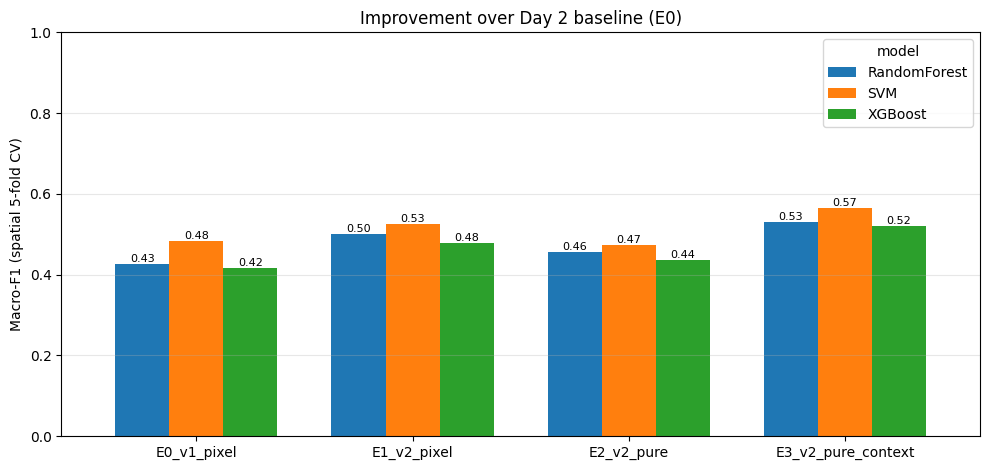

In [6]:
piv = exp.pivot(index='experiment', columns='model', values='macro_f1').loc[[e[0] for e in EXPERIMENTS]]
ax = piv.plot(kind='bar', figsize=(10, 4.8), rot=0, width=0.75)
ax.set_ylabel('Macro-F1 (spatial 5-fold CV)'); ax.set_xlabel('')
ax.set_title('Improvement over Day 2 baseline (E0)'); ax.set_ylim(0, 1); ax.grid(axis='y', alpha=0.3)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8)
plt.tight_layout(); plt.savefig(f'{RES}/improvement_macro_f1.png', dpi=150); plt.show()

## Part D – Best model: report, confusion matrix, cross-site transfer

🏆 Best: SVM · E3_v2_pure_context  macro-F1 0.565 (baseline E0 best 0.484, +0.081), OA 0.570, kappa 0.427
       model  accuracy  macro_f1  kappa  cv_time_s
         SVM     0.570     0.565  0.427        1.2
RandomForest     0.537     0.530  0.383       12.3
     XGBoost     0.525     0.521  0.367        7.0

               precision    recall  f1-score   support

        Sand      0.561     0.408     0.473       600
      Rubble      0.560     0.603     0.581       600
        Rock      0.611     0.697     0.651       600
 Coral/Algae      0.543     0.572     0.557       600

    accuracy                          0.570      2400
   macro avg      0.568     0.570     0.565      2400
weighted avg      0.568     0.570     0.565      2400



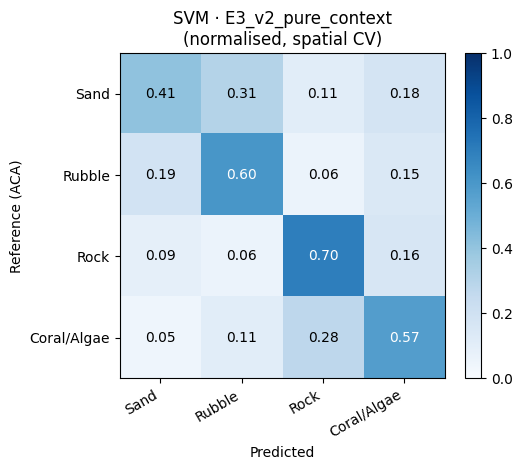

train test  accuracy  macro_f1
  HKD  PGI     0.549     0.512
  PGI  HKD     0.352     0.323


In [7]:
best = exp.sort_values('macro_f1', ascending=False).iloc[0]
BEST_EXP, BEST_MODEL = best['experiment'], best['model']
base = exp[exp.experiment == 'E0_v1_pixel'].macro_f1.max()
print(f'🏆 Best: {BEST_MODEL} · {BEST_EXP}  macro-F1 {best.macro_f1:.3f} (baseline E0 best {base:.3f}, '
      f'{best.macro_f1 - base:+.3f}), OA {best.accuracy:.3f}, kappa {best.kappa:.3f}')

comp = exp[exp.experiment == BEST_EXP].sort_values('macro_f1', ascending=False)[['model', 'accuracy', 'macro_f1', 'kappa', 'cv_time_s']]
comp.to_csv(f'{RES}/model_comparison.csv', index=False)
print(comp.round(3).to_string(index=False))

y_, p_ = preds[(BEST_EXP, BEST_MODEL)]
print('\n', classification_report(y_, p_, target_names=labels_txt, digits=3))
cm = confusion_matrix(y_, p_, normalize='true')
fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(labels_txt, rotation=30, ha='right')
ax.set_yticks(range(4)); ax.set_yticklabels(labels_txt)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > 0.5 else 'black')
ax.set_xlabel('Predicted'); ax.set_ylabel('Reference (ACA)'); ax.set_title(f'{BEST_MODEL} · {BEST_EXP}\n(normalised, spatial CV)')
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(f'{RES}/confusion_matrix.png', dpi=150); plt.show()

feats = dict((e[0], e[3]) for e in EXPERIMENTS)[BEST_EXP]
dfb = datasets[BEST_EXP]
transfer = []
for tr_, te_ in [('HKD', 'PGI'), ('PGI', 'HKD')]:
    m = get_models()[BEST_MODEL]
    a, b = dfb.site == tr_, dfb.site == te_
    m.fit(dfb.loc[a, feats].values, le.transform(dfb.loc[a, 'label']))
    pt, yt = m.predict(dfb.loc[b, feats].values), le.transform(dfb.loc[b, 'label'])
    transfer.append({'train': tr_, 'test': te_, 'accuracy': accuracy_score(yt, pt), 'macro_f1': f1_score(yt, pt, average='macro')})
pd.DataFrame(transfer).to_csv(f'{RES}/cross_site_transfer.csv', index=False)
print(pd.DataFrame(transfer).round(3).to_string(index=False))

## Part E – Final model save + maps (majority filter ekka)

In [8]:
import sklearn, xgboost
X_all, y_all = dfb[feats].values, le.transform(dfb['label'])
final = get_models()[BEST_MODEL].fit(X_all, y_all)
use_neigh = any('_m' in f or '_s' in f for f in feats)
bundle = {'model': final, 'le': le, 'name': BEST_MODEL, 'feature_set': BEST_EXP, 'experiment': BEST_EXP,
          'features': feats, 'feature_spec': {'glint_dark_pct': 10, 'neigh_sizes': [3, 5] if use_neigh else []},
          'smooth_size': 3, 'glint_dark_pct': 10, 'class_names': CLASS_NAMES,
          'composite_version': dict((e[0], e[1]) for e in EXPERIMENTS)[BEST_EXP],
          'cv_macro_f1': float(best.macro_f1), 'cv_accuracy': float(best.accuracy),
          'versions': {'sklearn': sklearn.__version__, 'xgboost': xgboost.__version__}}
old = f'{MOD}/best_model.joblib'
if os.path.exists(old) and not os.path.exists(f'{MOD}/best_model_v1.joblib'):
    shutil.copy(old, f'{MOD}/best_model_v1.joblib')     # keep Day 2 baseline model
joblib.dump(bundle, old)
print('✅ Saved models/best_model.joblib (Day 2 model kept as best_model_v1.joblib)')
print('Versions:', bundle['versions'], '| composite:', bundle['composite_version'])

✅ Saved models/best_model.joblib (Day 2 model kept as best_model_v1.joblib)
Versions: {'sklearn': '1.6.1', 'xgboost': '3.4.1'} | composite: v2


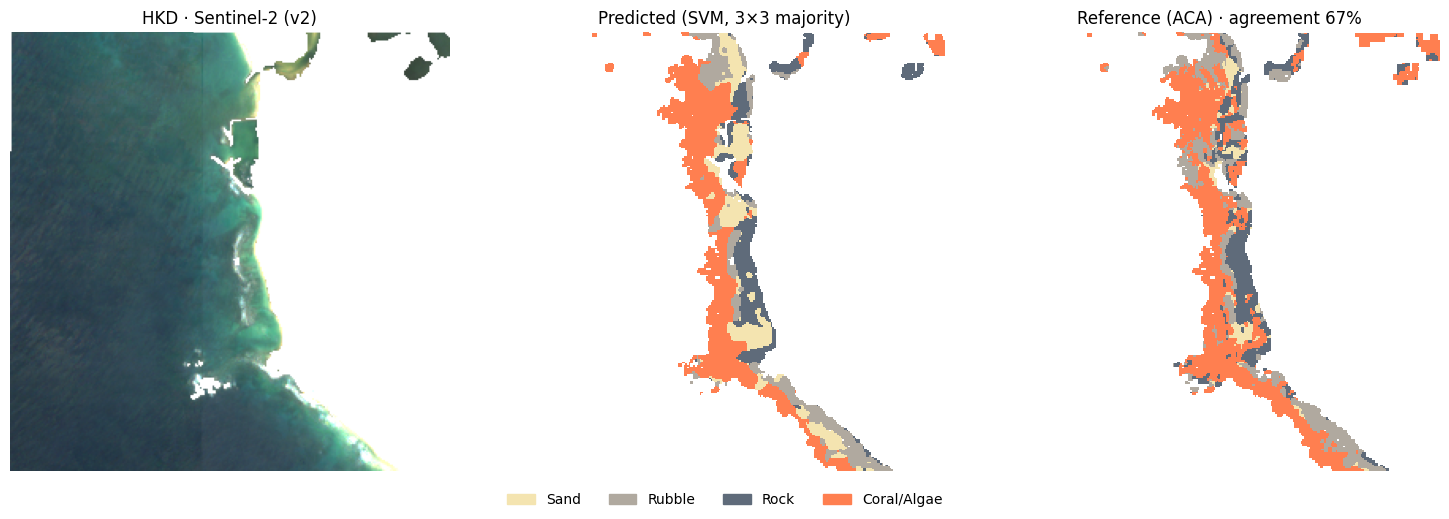

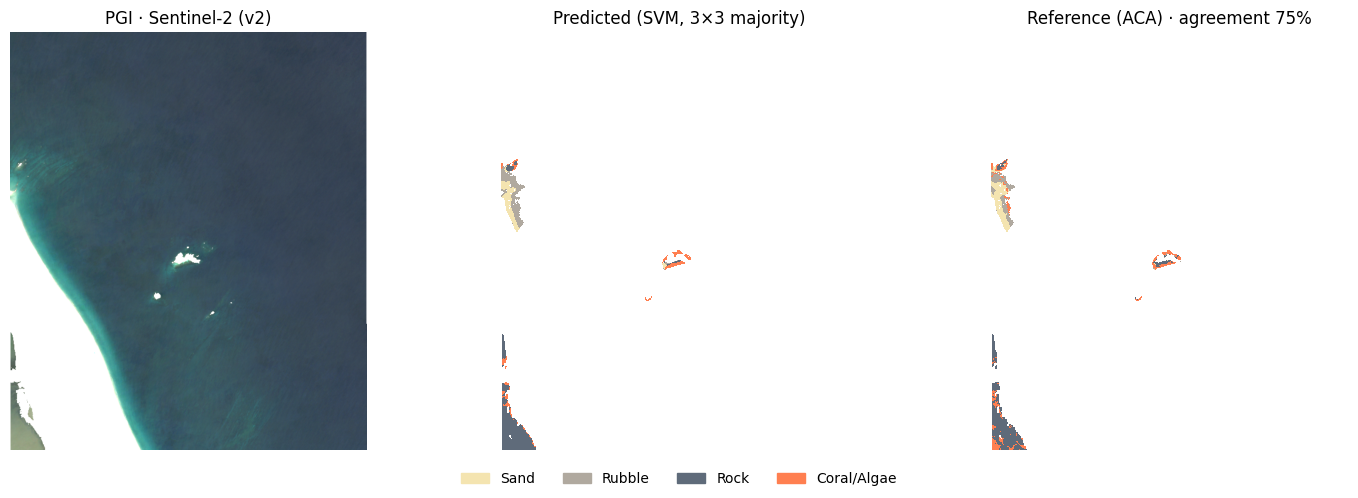

site  agreement_raw  agreement_smoothed
 HKD          0.666               0.672
 PGI          0.741               0.745
site          HKD   PGI
class                  
Coral/Algae  47.5  13.9
Rock         16.9  49.7
Rubble       17.6  21.2
Sand         18.0  15.2


In [9]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

def majority_filter(pred, valid, codes, size=3):
    counts = np.stack([uniform_filter(((pred == c) & valid).astype('float32'), size, mode='nearest') for c in codes])
    return np.where(valid, np.asarray(codes)[counts.argmax(0)], 0).astype(pred.dtype)

cmap = ListedColormap([CLASS_COLORS[c] for c in CODES])
norm = BoundaryNorm([c - 0.5 for c in CODES] + [CODES[-1] + 0.5], cmap.N)
cover_rows, agree_rows = [], []
for s in SITES:
    d = data[(bundle['composite_version'], s)]
    X = np.stack([d['f'][k] for k in feats], axis=-1)
    valid = np.isfinite(X).all(-1) & np.isin(d['lab'], CODES)
    raw = np.zeros(d['lab'].shape, np.uint8)
    raw[valid] = le.inverse_transform(final.predict(X[valid]))
    smooth = majority_filter(raw, valid, CODES, 3)
    a_raw, a_sm = (raw[valid] == d['lab'][valid]).mean(), (smooth[valid] == d['lab'][valid]).mean()
    agree_rows.append({'site': s, 'agreement_raw': a_raw, 'agreement_smoothed': a_sm})

    out = d['prof'].copy(); out.update(count=1, dtype='uint8', nodata=0)
    with rasterio.open(f'{RES}/classified_{s}.tif', 'w', **out) as dst:
        dst.write(smooth, 1)
    vals, cnt = np.unique(smooth[valid], return_counts=True)
    for v_, n in zip(vals, cnt):
        cover_rows.append({'site': s, 'class': CLASS_NAMES[int(v_)], 'pixels': int(n), 'area_ha': n / 100, 'cover_pct': 100 * n / cnt.sum()})

    rgb = np.nan_to_num(np.clip(np.stack([d['arr'][2], d['arr'][1], d['arr'][0]], -1) / 0.15, 0, 1), nan=1.0)
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    axs[0].imshow(rgb); axs[0].set_title(f'{s} · Sentinel-2 ({bundle["composite_version"]})')
    axs[1].imshow(np.ma.masked_equal(smooth, 0), cmap=cmap, norm=norm, interpolation='nearest')
    axs[1].set_title(f'Predicted ({BEST_MODEL}, 3×3 majority)')
    axs[2].imshow(np.ma.masked_where(~np.isin(d['lab'], CODES), d['lab']), cmap=cmap, norm=norm, interpolation='nearest')
    axs[2].set_title(f'Reference (ACA) · agreement {a_sm:.0%}')
    for a in axs: a.axis('off')
    fig.legend(handles=[Patch(color=CLASS_COLORS[c], label=CLASS_NAMES[c]) for c in CODES], loc='lower center', ncol=4, frameon=False)
    plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.savefig(f'{RES}/map_{s}.png', dpi=150); plt.show()

pd.DataFrame(cover_rows).to_csv(f'{RES}/benthic_cover.csv', index=False)
pd.DataFrame(agree_rows).to_csv(f'{RES}/map_agreement.csv', index=False)
print(pd.DataFrame(agree_rows).round(3).to_string(index=False))
print(pd.DataFrame(cover_rows).pivot(index='class', columns='site', values='cover_pct').round(1))

✅ **Check:** maps 2, agreement table (raw vs smoothed), cover %.
⚠️ Map agreement eke training pixels thiyena nisa optimistic. **Real accuracy = Part C spatial-CV results.**

In [10]:
for folder in [RES, MOD]:
    print(folder)
    for fn in sorted(os.listdir(folder)):
        print(f'   {fn:32s} {os.path.getsize(os.path.join(folder, fn)) / 1024:8.1f} KB')

/content/drive/MyDrive/coral_c3/results_v2
   ablation_results.csv                  1.1 KB
   benthic_cover.csv                     0.4 KB
   classified_HKD.tif                    4.2 KB
   classified_PGI.tif                    7.3 KB
   confusion_matrix.png                 64.7 KB
   cross_site_transfer.csv               0.1 KB
   experiment_results.csv                1.1 KB
   improvement_macro_f1.png             51.8 KB
   map_HKD.png                         377.8 KB
   map_PGI.png                         467.0 KB
   map_agreement.csv                     0.1 KB
   model_comparison.csv                  0.2 KB
/content/drive/MyDrive/coral_c3/models
   best_model.joblib                   224.1 KB
   best_model_v1.joblib                140.1 KB


🎉 **Day 2b iwarai!** Chat ekata ewanna:
1. Part C **Macro-F1 table** eka
2. Part D **🏆 Best** line + classification report + transfer table
3. Part E agreement table + **Versions** line
4. Screenshots: `improvement_macro_f1.png`, `confusion_matrix.png`, `map_HKD.png`